In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
while running:
    compute_all_forces()     # sum forces on every body
    integrator.step(dt)      # advance state by fixed dt
    handle_collisions()      # detect and resolve
    record_or_render()       # store data (Python) or draw (JS later)

NameError: name 'running' is not defined

In [4]:
class Body:
    def __init__(self, mass, pos, vel, radius=0.1, I=None):
        self.m = mass
        self.r = np.array(pos, dtype=float)
        self.v = np.array(vel, dtype=float)
        self.radius = radius
        self.theta = 0.0      # orientation
        self.omega = 0.0      # angular velocity
        self.I = I if I is not None else 0.5*mass*radius**2
        self.force = np.zeros(2)   # accumulator, reset each step
        self.torque = 0.0

    def clear_accumulators(self):
        self.force = np.zeros(2)
        self.torque = 0.0

In [5]:
class Gravity:
    def __init__(self, g=9.81):
        self.g = np.array([0.0, -g])
    def apply(self, world):
        for b in world.bodies:
            b.force += b.m * self.g        # F = mg

class Drag:
    def __init__(self, c):
        self.c = c
    def apply(self, world):
        for b in world.bodies:
            b.force += -self.c * np.linalg.norm(b.v) * b.v   # quadratic drag

In [6]:
class EulerCromer:
    def step(self, world, dt):
        for b in world.bodies:
            a = b.force / b.m
            b.v += a * dt
            b.r += b.v * dt
            alpha = b.torque / b.I
            b.omega += alpha * dt
            b.theta += b.omega * dt

In [7]:
class World:
    def __init__(self, integrator):
        self.bodies = []
        self.forces = []
        self.integrator = integrator
        self.time = 0.0

    def add_body(self, body):  self.bodies.append(body)
    def add_force(self, force): self.forces.append(force)

    def step(self, dt):
        for b in self.bodies:
            b.clear_accumulators()
        for f in self.forces:
            f.apply(self)                 # each force adds to body accumulators
        self.integrator.step(self, dt)    # advance state
        self.handle_collisions()          # detect + resolve
        self.time += dt

    def handle_collisions(self):
        pass   # fill in using your Lab 4 collision code

✍️ Try it: Reproduce Lab 1's projectile in six lines — world = World(EulerCromer()); world.add_body(Body(1, [0,0], [15,20])); world.add_force(Gravity()), then loop world.step(0.01) and record positions. If your old lab and your new engine agree, your architecture is sound.

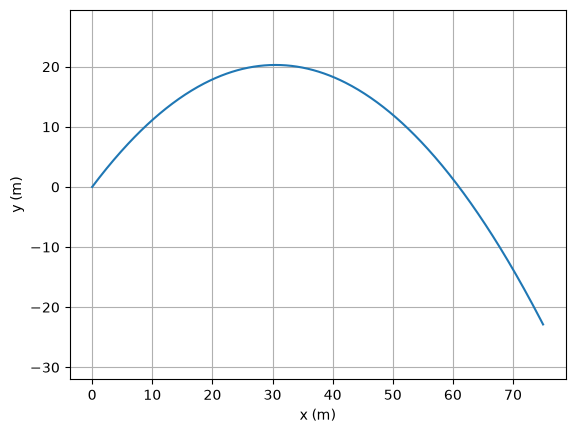

In [8]:
world = World(EulerCromer())
world.add_body(Body(1, [0, 0], [15, 20]))
world.add_force(Gravity())
dt = 0.01
positions = [world.bodies[0].r.copy()]
for _ in range(500):
    world.step(dt)
    positions.append(world.bodies[0].r.copy())
positions = np.array(positions)
plt.plot(positions[:, 0], positions[:, 1])
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.axis("equal")
plt.grid(True)
plt.show()